In [1]:

from google.colab import files

uploaded = files.upload()


Saving dataset (1).csv to dataset (1).csv
Saving data_dictionary (4).csv to data_dictionary (4).csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify uploaded files
dataset_file = next(
    f for f in uploaded
    if f.lower().startswith("dataset") and f.lower().endswith(".csv")
)

dictionary_file = next(
    f for f in uploaded
    if f.lower().startswith("data_dictionary") and f.lower().endswith(".csv")
)

# Load datasets
df = pd.read_csv(dataset_file)
data_dictionary = pd.read_csv(dictionary_file)

print("Both datasets loaded successfully!")
print("Main Dataset Shape:", df.shape)
print("Data Dictionary Shape:", data_dictionary.shape)


Both datasets loaded successfully!
Main Dataset Shape: (500, 8)
Data Dictionary Shape: (8, 7)


In [3]:

print("MAIN DATASET")
display(df.head())

print("\nDATA DICTIONARY")
display(data_dictionary.head())

print("\nCOLUMN INFORMATION")
df.info()


MAIN DATASET


,resume_id,job_role,years_exp,skills_matched,education_score,keyword_density,predicted_score,shortlisted
0,R0001,Data_Analyst,3,8,73,0.129,46.1,0
1,R0002,Data_Analyst,5,6,67,0.747,97.7,1
2,R0003,Software_Engineer,9,11,89,0.713,61.1,1
3,R0004,HR_Executive,4,8,99,0.459,79.9,0
4,R0005,Software_Engineer,10,4,91,0.608,57.8,1



DATA DICTIONARY


,column_name,data_type,sample_value_1,sample_value_2,sample_value_3,nullable,description_fill_in
0,resume_id,object/numeric,R0001,R0002,R0003,No,resume_id — [Learner to fill in description]
1,job_role,object/numeric,Data_Analyst,Data_Analyst,Software_Engineer,No,job_role — [Learner to fill in description]
2,years_exp,object/numeric,3,5,9,No,years_exp — [Learner to fill in description]
3,skills_matched,object/numeric,8,6,11,No,skills_matched — [Learner to fill in description]
4,education_score,object/numeric,73,67,89,No,education_score — [Learner to fill in descript...



COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resume_id        500 non-null    object 
 1   job_role         500 non-null    object 
 2   years_exp        500 non-null    int64  
 3   skills_matched   500 non-null    int64  
 4   education_score  500 non-null    int64  
 5   keyword_density  500 non-null    float64
 6   predicted_score  500 non-null    float64
 7   shortlisted      500 non-null    int64  
dtypes: float64(2), int64(4), object(2)
memory usage: 31.4+ KB


In [4]:

print("MISSING VALUE ANALYSIS")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())


MISSING VALUE ANALYSIS
resume_id          0
job_role           0
years_exp          0
skills_matched     0
education_score    0
keyword_density    0
predicted_score    0
shortlisted        0
dtype: int64

Total Missing Values: 0


In [5]:

print("DUPLICATE ANALYSIS")

print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Resume IDs:",
      df["resume_id"].duplicated().sum())


DUPLICATE ANALYSIS
Duplicate Rows: 0
Duplicate Resume IDs: 0


In [6]:

print("STATISTICAL SUMMARY")

display(df.describe())

print("\nCATEGORICAL COLUMN SUMMARY")

display(df.describe(include="object"))


STATISTICAL SUMMARY


,years_exp,skills_matched,education_score,keyword_density,predicted_score,shortlisted
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000
mean,7.458000,8.848000,80.314000,0.491682,68.033400,0.34600
std,4.698978,3.729439,11.979416,0.226735,17.569519,0.47617
min,0.000000,3.000000,60.000000,0.101000,40.100000,0.00000
25%,3.000000,6.000000,69.000000,0.295750,51.300000,0.00000
50%,7.000000,9.000000,80.000000,0.492500,67.700000,0.00000
75%,12.000000,12.000000,91.000000,0.697250,83.300000,1.00000
max,15.000000,15.000000,100.000000,0.900000,100.000000,1.00000



CATEGORICAL COLUMN SUMMARY


,resume_id,job_role
count,500,500
unique,500,5
top,R0001,HR_Executive
freq,1,120


In [7]:

print("SHORTLISTING DISTRIBUTION")

print(df["shortlisted"].value_counts())

print("\nPercentage Distribution:")

print(
    (df["shortlisted"].value_counts(normalize=True) * 100)
    .round(2)
)


SHORTLISTING DISTRIBUTION
shortlisted
0    327
1    173
Name: count, dtype: int64

Percentage Distribution:
shortlisted
0    65.4
1    34.6
Name: proportion, dtype: float64


In [8]:

print("JOB ROLE DISTRIBUTION")

print(df["job_role"].value_counts())


JOB ROLE DISTRIBUTION
job_role
HR_Executive         120
QA_Engineer          104
Data_Analyst         102
Software_Engineer     87
Project_Manager       87
Name: count, dtype: int64


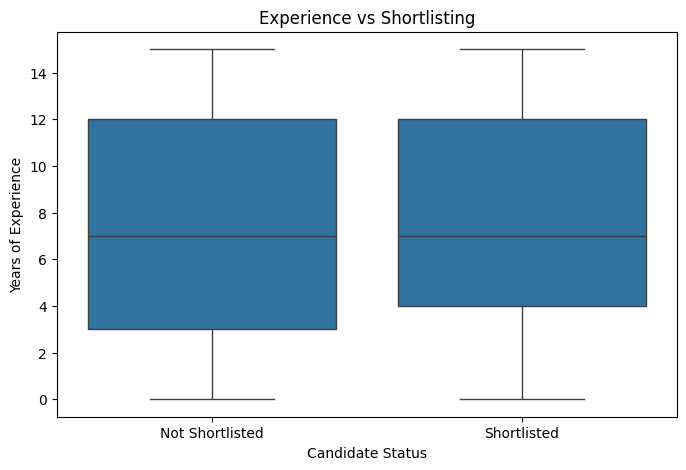

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="shortlisted", y="years_exp")

plt.title("Experience vs Shortlisting")
plt.xticks([0, 1], ["Not Shortlisted", "Shortlisted"])
plt.xlabel("Candidate Status")
plt.ylabel("Years of Experience")

plt.show()

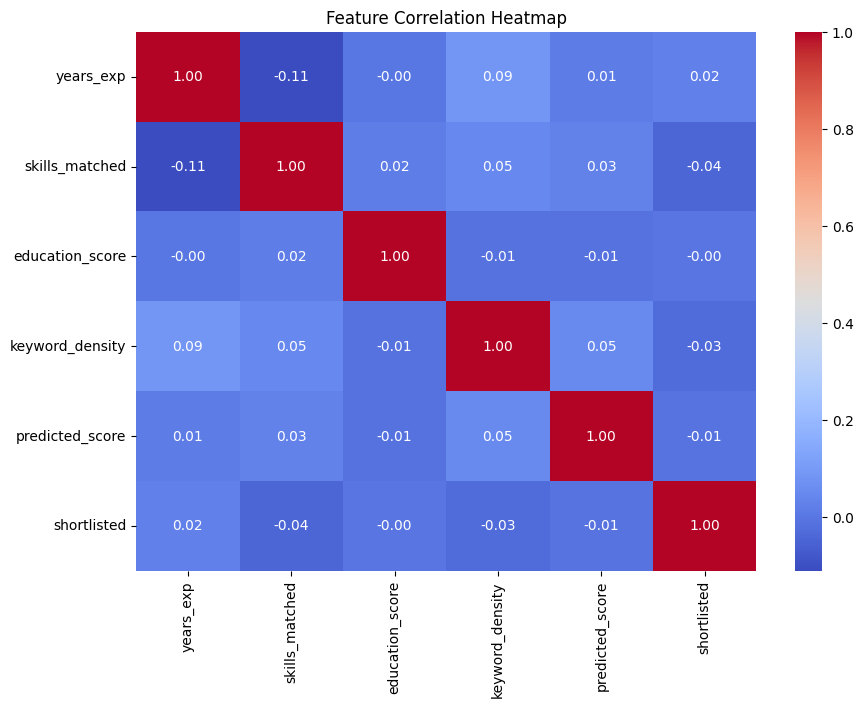

In [10]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [11]:
print("Predicted Score by Shortlisting Status:")

display(
    df.groupby("shortlisted")["predicted_score"]
    .agg(["mean", "min", "max", "count"])
)

print("\nCorrelation with Shortlisted:")

print(
    df.select_dtypes(include=np.number)
    .corr()["shortlisted"]
    .sort_values(ascending=False)
)

Predicted Score by Shortlisting Status:


,mean,min,max,count
shortlisted,,,,
0,68.142202,40.1,99.8,327
1,67.827746,40.1,100.0,173



Correlation with Shortlisted:
shortlisted        1.000000
years_exp          0.024868
education_score   -0.003626
predicted_score   -0.008522
keyword_density   -0.029309
skills_matched    -0.043677
Name: shortlisted, dtype: float64


Separate features and target

In [12]:

# Separate input features and target variable

X = df.drop(
    columns=["resume_id", "shortlisted"]
)

y = df["shortlisted"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())


Feature Shape: (500, 6)
Target Shape: (500,)

Input Features:
['job_role', 'years_exp', 'skills_matched', 'education_score', 'keyword_density', 'predicted_score']

Target Distribution:
shortlisted
0    327
1    173
Name: count, dtype: int64


Encode categorical features

In [13]:

X = pd.get_dummies(
    X,
    columns=["job_role"],
    drop_first=False,
    dtype=int
)

print("Encoding completed!")
print("New Feature Shape:", X.shape)

display(X.head())


Encoding completed!
New Feature Shape: (500, 10)


,years_exp,skills_matched,education_score,keyword_density,predicted_score,job_role_Data_Analyst,job_role_HR_Executive,job_role_Project_Manager,job_role_QA_Engineer,job_role_Software_Engineer
0,3,8,73,0.129,46.1,1,0,0,0,0
1,5,6,67,0.747,97.7,1,0,0,0,0
2,9,11,89,0.713,61.1,0,0,0,0,1
3,4,8,99,0.459,79.9,0,1,0,0,0
4,10,4,91,0.608,57.8,0,0,0,0,1


Train-test split

In [14]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features: (400, 10)
Testing Features: (100, 10)

Training Target Distribution:
shortlisted
0    262
1    138
Name: count, dtype: int64

Testing Target Distribution:
shortlisted
0    65
1    35
Name: count, dtype: int64


Import evaluation libraries

In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


Train three ML models

In [16]:

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


Evaluate model performance

In [17]:

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.65,0.5000,0.1143,0.1860
1,Decision Tree,0.64,0.3333,0.0286,0.0526
0,Logistic Regression,0.65,0.0000,0.0000,0.0000


Generate classification reports

In [18]:

for name, model in models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Shortlisted",
            "Shortlisted"
        ],
        zero_division=0
    ))



Logistic Regression
                 precision    recall  f1-score   support

Not Shortlisted       0.65      1.00      0.79        65
    Shortlisted       0.00      0.00      0.00        35

       accuracy                           0.65       100
      macro avg       0.33      0.50      0.39       100
   weighted avg       0.42      0.65      0.51       100


Decision Tree
                 precision    recall  f1-score   support

Not Shortlisted       0.65      0.97      0.78        65
    Shortlisted       0.33      0.03      0.05        35

       accuracy                           0.64       100
      macro avg       0.49      0.50      0.42       100
   weighted avg       0.54      0.64      0.52       100


Random Forest
                 precision    recall  f1-score   support

Not Shortlisted       0.66      0.94      0.78        65
    Shortlisted       0.50      0.11      0.19        35

       accuracy                           0.65       100
      macro avg       0.58   

**Compare confusion matrices**

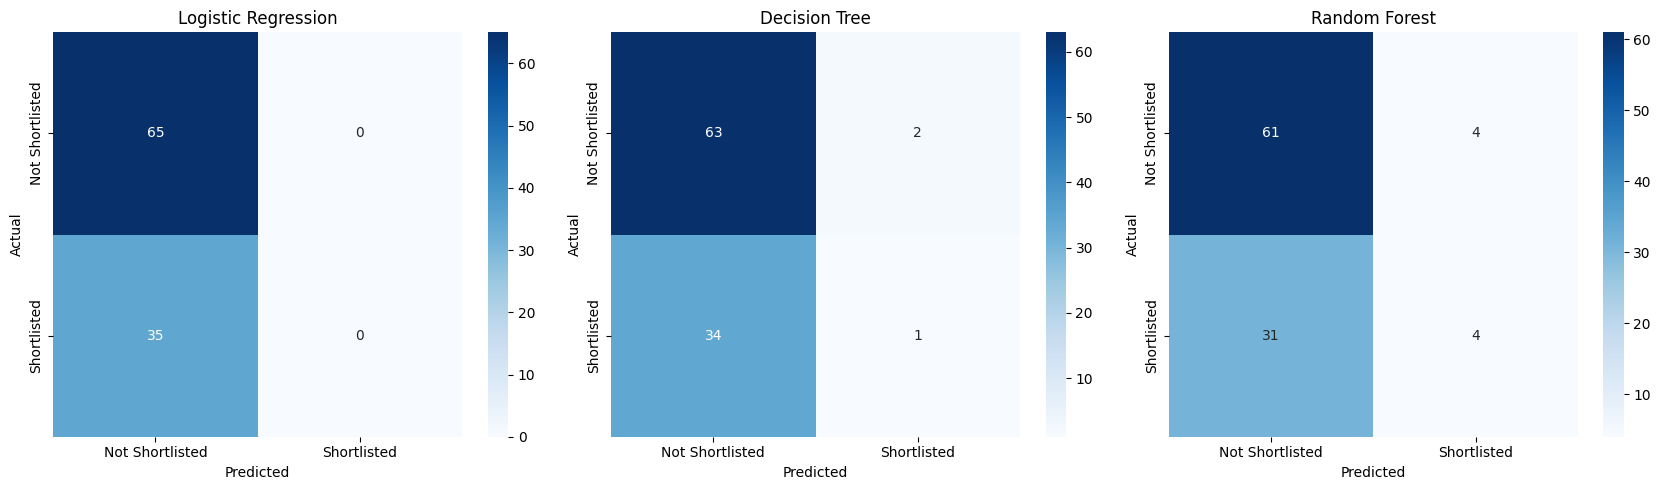

In [19]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Not Shortlisted", "Shortlisted"],
        yticklabels=["Not Shortlisted", "Shortlisted"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("BASELINE MODEL PERFORMANCE")

print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))

BASELINE MODEL PERFORMANCE
              precision    recall  f1-score   support

           0       0.65      1.00      0.79        65
           1       0.00      0.00      0.00        35

    accuracy                           0.65       100
   macro avg       0.33      0.50      0.39       100
weighted avg       0.42      0.65      0.51       100



In [21]:
print("SHORTLISTING BY JOB ROLE")

role_analysis = pd.crosstab(
    df["job_role"],
    df["shortlisted"],
    normalize="index"
) * 100

display(role_analysis.round(2))

SHORTLISTING BY JOB ROLE


shortlisted,0,1
job_role,,
Data_Analyst,66.67,33.33
HR_Executive,70.83,29.17
Project_Manager,58.62,41.38
QA_Engineer,64.42,35.58
Software_Engineer,64.37,35.63


In [22]:
print("FEATURE AVERAGES BY SHORTLISTING STATUS")

feature_analysis = df.groupby("shortlisted")[
    [
        "years_exp",
        "skills_matched",
        "education_score",
        "keyword_density",
        "predicted_score"
    ]
].mean()

display(feature_analysis.round(2))

FEATURE AVERAGES BY SHORTLISTING STATUS


,years_exp,skills_matched,education_score,keyword_density,predicted_score
shortlisted,,,,,
0,7.37,8.97,80.35,0.50,68.14
1,7.62,8.62,80.25,0.48,67.83


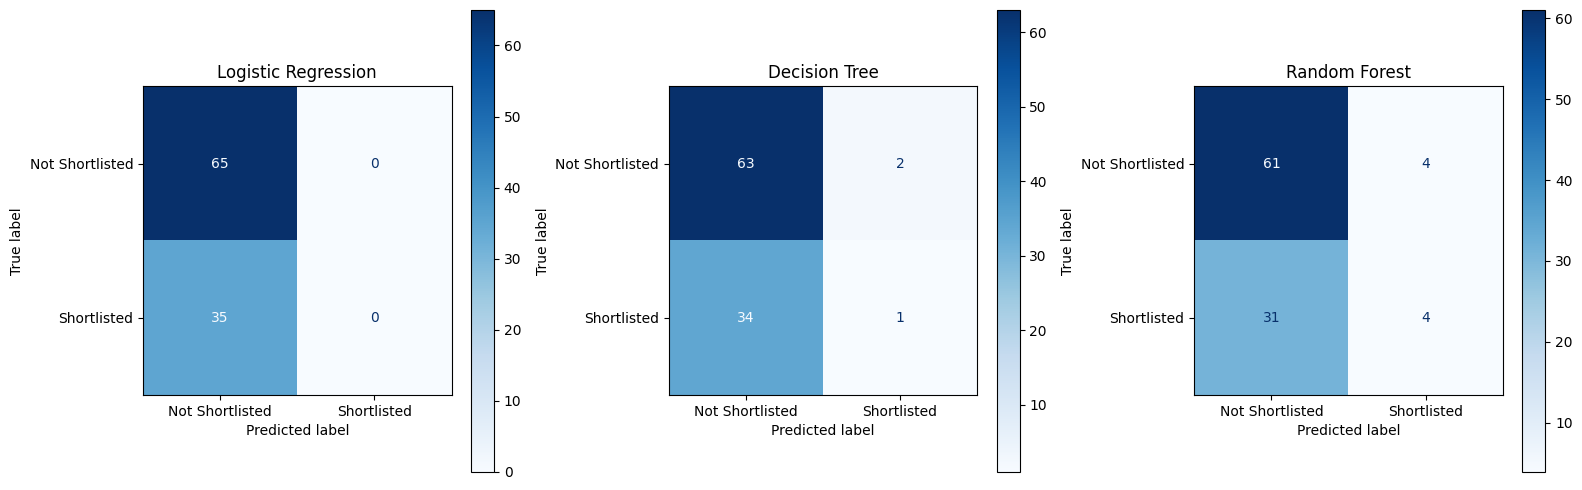

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Not Shortlisted", "Shortlisted"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [25]:
feature_analysis = df.groupby("shortlisted")[
    [
        "years_exp",
        "skills_matched",
        "education_score",
        "keyword_density",
        "predicted_score"
    ]
].mean()

display(feature_analysis.round(2))

,years_exp,skills_matched,education_score,keyword_density,predicted_score
shortlisted,,,,,
0,7.37,8.97,80.35,0.50,68.14
1,7.62,8.62,80.25,0.48,67.83


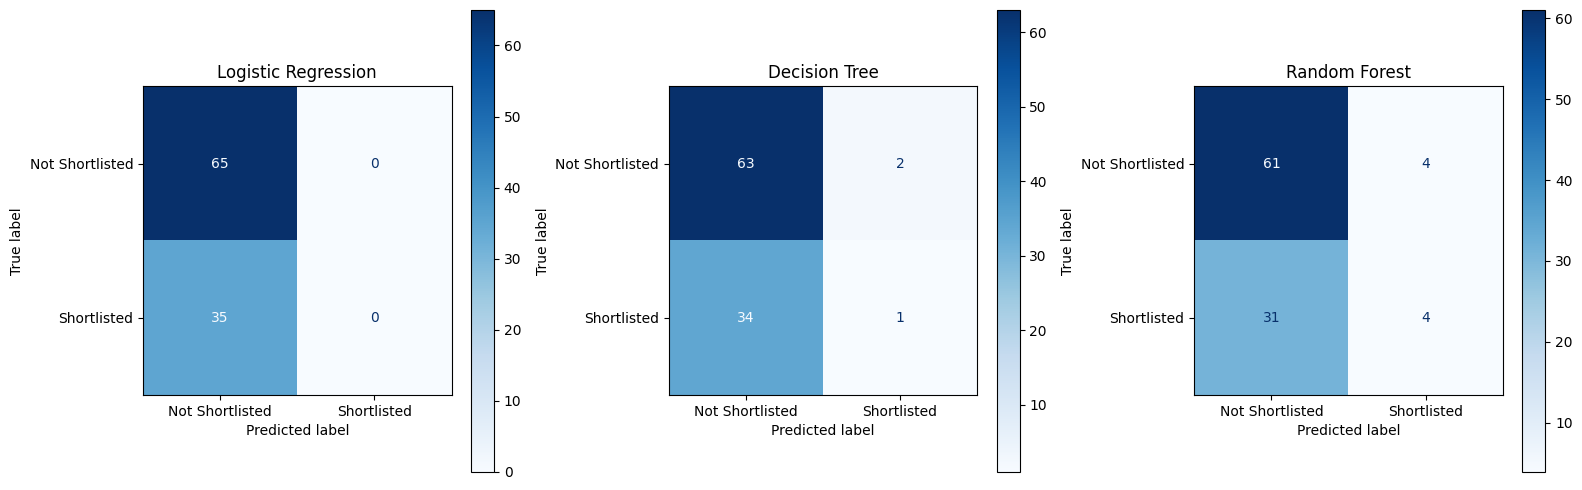

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Not Shortlisted", "Shortlisted"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

,Feature,Importance
4,predicted_score,0.218615
3,keyword_density,0.217684
2,education_score,0.183530
0,years_exp,0.144868
1,skills_matched,0.128487
6,job_role_HR_Executive,0.025015
7,job_role_Project_Manager,0.023233
8,job_role_QA_Engineer,0.021307
5,job_role_Data_Analyst,0.020507
9,job_role_Software_Engineer,0.016753


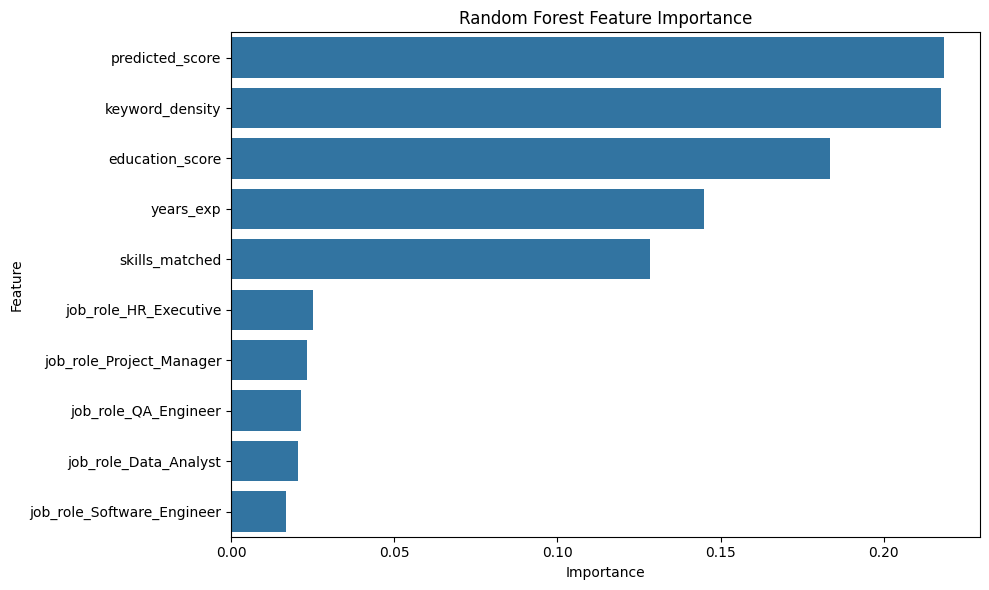

In [27]:
rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [28]:
rf_model = models["Random Forest"]

probabilities = rf_model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6]:

    predictions = (probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Precision:",
          precision_score(y_test, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_test, predictions, zero_division=0))

    print("F1 Score:",
          f1_score(y_test, predictions, zero_division=0))


Threshold: 0.3
Precision: 0.3670886075949367
Recall: 0.8285714285714286
F1 Score: 0.5087719298245614

Threshold: 0.4
Precision: 0.3783783783783784
Recall: 0.4
F1 Score: 0.3888888888888889

Threshold: 0.5
Precision: 0.5
Recall: 0.11428571428571428
F1 Score: 0.18604651162790697

Threshold: 0.6
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [29]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    models["Random Forest"],
    "models/random_forest_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [30]:
!pip install spacy pdfminer.six scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 25.7 MB/s  0:00:00


In [31]:
import spacy

from pdfminer.high_level import extract_text
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("NLP libraries imported successfully!")

NLP libraries imported successfully!


In [33]:

import spacy
import re
import os
import pandas as pd

from google.colab import files
from pdfminer.high_level import extract_text

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Load spaCy English pipeline
nlp = spacy.blank("en")

print("NLP environment initialized successfully!")


NLP environment initialized successfully!


In [34]:

def extract_resume_text(pdf_path):

    try:
        text = extract_text(pdf_path)

        if not text or not text.strip():
            return ""

        # Remove unnecessary whitespace
        text = re.sub(r'\s+', ' ', text)

        return text.strip()

    except Exception as e:
        print("Error extracting resume:", e)
        return ""


In [35]:

SKILLS = [
    "python", "java", "c++", "c", "javascript",
    "react", "html", "css", "sql", "mysql",
    "mongodb", "flask", "django", "spring boot",
    "machine learning", "deep learning",
    "artificial intelligence", "data analysis",
    "pandas", "numpy", "scikit-learn",
    "tensorflow", "pytorch", "nlp",
    "git", "github", "docker", "aws",
    "excel", "power bi", "tableau",
    "communication", "leadership",
    "project management"
]

def extract_skills(text):

    text_lower = text.lower()

    found_skills = []

    for skill in SKILLS:

        pattern = r'(?<!\w)' + re.escape(skill) + r'(?!\w)'

        if re.search(pattern, text_lower):
            found_skills.append(skill)

    return found_skills


In [36]:

def extract_experience(text):

    patterns = [
        r'(\d+)\+?\s*(?:years|yrs)\s+(?:of\s+)?experience',
        r'experience\s*(?:of)?\s*(\d+)\+?\s*(?:years|yrs)'
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            text.lower()
        )

        if match:
            return int(match.group(1))

    return 0


In [37]:
uploaded_resumes = files.upload()

Saving Sample_Resume_Data_Analyst.pdf to Sample_Resume_Data_Analyst.pdf
Saving Sample_Resume_QA_Engineer.pdf to Sample_Resume_QA_Engineer.pdf
Saving Sample_Resume_Software_Engineer.pdf to Sample_Resume_Software_Engineer.pdf


In [46]:
resume_records = []

for filename in uploaded_resumes:

    if not filename.lower().endswith(".pdf"):
        print("Skipping non-PDF file:", filename)
        continue

    text = extract_resume_text(filename)

    if not text:
        print("No extractable text:", filename)
        continue

    skills = extract_skills(text)
    experience = extract_experience(text)

    resume_records.append({
        "resume_id": filename,
        "resume_text": text,
        "skills": skills,
        "skills_matched": len(skills),
        "years_exp": experience
    })

    print("\nProcessed:", filename)
    print("Skills:", skills)
    print("Experience:", experience)

resume_df = pd.DataFrame(resume_records)

display(
    resume_df.drop(columns=["resume_text"])
)


Processed: Sample_Resume_Data_Analyst.pdf
Skills: ['python', 'sql', 'data analysis', 'pandas', 'numpy', 'scikit-learn', 'excel', 'power bi', 'tableau', 'matplotlib', 'software testing']
Experience: 2

Processed: Sample_Resume_QA_Engineer.pdf
Skills: ['python', 'java', 'sql', 'mysql', 'git', 'software testing', 'manual testing', 'regression testing', 'api testing', 'selenium', 'defect tracking', 'rest apis', 'communication']
Experience: 4

Processed: Sample_Resume_Software_Engineer.pdf
Skills: ['python', 'java', 'javascript', 'react', 'html', 'css', 'mysql', 'mongodb', 'flask', 'spring boot', 'git', 'github', 'software testing', 'rest apis']
Experience: 3


,resume_id,skills,skills_matched,years_exp
0,Sample_Resume_Data_Analyst.pdf,"[python, sql, data analysis, pandas, numpy, sc...",11,2
1,Sample_Resume_QA_Engineer.pdf,"[python, java, sql, mysql, git, software testi...",13,4
2,Sample_Resume_Software_Engineer.pdf,"[python, java, javascript, react, html, css, m...",14,3


In [39]:
display(
    resume_df.drop(columns=["resume_text"])
)

,resume_id,skills,skills_matched,years_exp
0,Sample_Resume_Data_Analyst.pdf,"[python, sql, data analysis, pandas, numpy, sc...",9,0
1,Sample_Resume_QA_Engineer.pdf,"[python, java, sql, mysql, git, communication]",6,4
2,Sample_Resume_Software_Engineer.pdf,"[python, java, javascript, react, html, css, m...",12,0


In [40]:
for index, row in resume_df.iterrows():

    print("\n" + "=" * 60)
    print("RESUME:", row["resume_id"])
    print("=" * 60)

    print(row["resume_text"][:1000])


RESUME: Sample_Resume_Data_Analyst.pdf
Aarav Sharma Entry-Level Data Analyst aarav.sharma@example.com | +91 90000 10001 | India PROFESSIONAL SUMMARY Entry-level data analyst with 2 years of internship and project experience turning structured data into actionable reports. Interested in analytics, dashboarding, and data quality. EDUCATION B.Tech, Computer Science, North Valley Institute of Technology — 2024 EXPERIENCE & PROJECTS Data Analyst Intern | Insight Metrics | Jan 2023 – Dec 2023 (cid:127) Cleaned and analyzed datasets using Python, Pandas, and NumPy. (cid:127) Created SQL queries and Power BI dashboards for weekly reporting. (cid:127) Used Excel to validate records and identify data-quality issues. Academic Project | Customer Churn Analysis | 2024 (cid:127) Built a scikit-learn classification baseline and evaluated it using precision, recall, and F1-score. (cid:127) Presented findings with Matplotlib visualizations. TECHNICAL SKILLS Python, SQL, Pandas, NumPy, Excel, Power BI,

In [41]:
def extract_experience(text):
    patterns = [
        r'(\d+)\+?\s*(?:years|yrs)(?:\s+of)?\s+(?:[\w]+\s+){0,5}experience',
        r'experience\s*(?:of)?\s*(\d+)\+?\s*(?:years|yrs)'
    ]

    for pattern in patterns:
        match = re.search(pattern, text.lower())
        if match:
            return int(match.group(1))

    return 0

In [42]:
resume_records = []

for filename in uploaded_resumes:
    if not filename.lower().endswith(".pdf"):
        continue

    text = extract_resume_text(filename)

    if not text:
        continue

    skills = extract_skills(text)
    experience = extract_experience(text)

    resume_records.append({
        "resume_id": filename,
        "skills": skills,
        "skills_matched": len(skills),
        "years_exp": experience
    })

resume_df = pd.DataFrame(resume_records)

display(resume_df)

,resume_id,skills,skills_matched,years_exp
0,Sample_Resume_Data_Analyst.pdf,"[python, sql, data analysis, pandas, numpy, sc...",9,2
1,Sample_Resume_QA_Engineer.pdf,"[python, java, sql, mysql, git, communication]",6,4
2,Sample_Resume_Software_Engineer.pdf,"[python, java, javascript, react, html, css, m...",12,3


In [43]:
job_descriptions = {
    "Data Analyst": """
        Python SQL data analysis pandas numpy Excel Power BI Tableau
        statistics data visualization machine learning
    """,

    "QA Engineer": """
        Software testing manual testing automation testing Selenium
        Python Java SQL API testing regression testing defect tracking
    """,

    "Software Engineer": """
        Python Java JavaScript React HTML CSS SQL MySQL MongoDB
        REST APIs Flask Django Spring Boot software development
    """,

    "HR Executive": """
        recruitment talent acquisition human resources communication
        employee engagement onboarding payroll HR management
    """,

    "Project Manager": """
        project management leadership communication Agile Scrum
        planning risk management team coordination Jira budgeting
    """
}

In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizer = TfidfVectorizer(stop_words="english")

job_roles = list(job_descriptions.keys())
job_texts = list(job_descriptions.values())

job_vectors = vectorizer.fit_transform(job_texts)

similarity_results = []

for _, row in resume_df.iterrows():

    resume_text = " ".join(row["skills"])

    resume_vector = vectorizer.transform([resume_text])

    similarities = cosine_similarity(
        resume_vector, job_vectors
    )[0]

    best_index = similarities.argmax()

    similarity_results.append({
        "resume_id": row["resume_id"],
        "recommended_role": job_roles[best_index],
        "similarity_score": round(
            similarities[best_index] * 100, 2
        )
    })

matching_df = pd.DataFrame(similarity_results)

display(matching_df)

,resume_id,recommended_role,similarity_score
0,Sample_Resume_Data_Analyst.pdf,Data Analyst,76.43
1,Sample_Resume_QA_Engineer.pdf,QA Engineer,91.37
2,Sample_Resume_Software_Engineer.pdf,Software Engineer,88.20


In [45]:
SKILLS = [
    "python", "java", "c++", "c", "javascript",
    "react", "html", "css", "sql", "mysql",
    "mongodb", "flask", "django", "spring boot",

    "machine learning", "deep learning",
    "artificial intelligence", "data analysis",
    "pandas", "numpy", "scikit-learn",
    "tensorflow", "pytorch", "nlp",

    "git", "github", "docker", "aws",
    "excel", "power bi", "tableau", "matplotlib",

    "software testing", "manual testing",
    "automation testing", "regression testing",
    "api testing", "selenium", "defect tracking",
    "software development", "rest apis",

    "communication", "leadership",
    "project management", "agile", "scrum",
    "jira", "recruitment", "talent acquisition",
    "human resources", "employee engagement"
]

In [48]:
role_requirements = {
    "Data Analyst": {
        "required_skills": [
            "python", "sql", "pandas", "numpy",
            "excel", "power bi", "tableau"
        ],
        "min_experience": 1
    },

    "QA Engineer": {
        "required_skills": [
            "software testing", "manual testing",
            "selenium", "api testing",
            "regression testing", "python", "java"
        ],
        "min_experience": 1
    },

    "Software Engineer": {
        "required_skills": [
            "python", "java", "javascript",
            "react", "sql", "rest apis",
            "git", "spring boot"
        ],
        "min_experience": 2
    },

    "HR Executive": {
        "required_skills": [
            "recruitment", "human resources",
            "communication", "employee engagement"
        ],
        "min_experience": 1
    },

    "Project Manager": {
        "required_skills": [
            "project management", "leadership",
            "agile", "scrum", "jira", "communication"
        ],
        "min_experience": 2
    }
}

In [49]:
final_results = []

for _, row in resume_df.iterrows():

    resume_id = row["resume_id"]

    match_row = matching_df[
        matching_df["resume_id"] == resume_id
    ].iloc[0]

    role = match_row["recommended_role"]

    requirements = role_requirements[role]

    candidate_skills = set(row["skills"])
    required_skills = set(requirements["required_skills"])

    matched_skills = candidate_skills.intersection(required_skills)

    skill_score = (
        len(matched_skills) / len(required_skills)
    ) * 100

    min_exp = requirements["min_experience"]

    experience_score = min(
        (row["years_exp"] / min_exp) * 100, 100
    )

    similarity_score = match_row["similarity_score"]

    final_score = (
        similarity_score * 0.50 +
        skill_score * 0.30 +
        experience_score * 0.20
    )

    final_results.append({
        "resume_id": resume_id,
        "recommended_role": role,
        "similarity_score": round(similarity_score, 2),
        "skill_score": round(skill_score, 2),
        "experience_score": round(experience_score, 2),
        "final_score": round(final_score, 2)
    })

final_df = pd.DataFrame(final_results)

display(final_df)

,resume_id,recommended_role,similarity_score,skill_score,experience_score,final_score
0,Sample_Resume_Data_Analyst.pdf,Data Analyst,76.43,100.0,100,88.22
1,Sample_Resume_QA_Engineer.pdf,QA Engineer,91.37,100.0,100,95.68
2,Sample_Resume_Software_Engineer.pdf,Software Engineer,88.20,87.5,100,90.35


In [50]:
SHORTLIST_THRESHOLD = 70

final_df["shortlist_status"] = final_df["final_score"].apply(
    lambda score: "Shortlisted"
    if score >= SHORTLIST_THRESHOLD
    else "Needs Human Review"
)

final_df = final_df.sort_values(
    by="final_score",
    ascending=False
).reset_index(drop=True)

final_df.insert(
    0,
    "rank",
    range(1, len(final_df) + 1)
)

display(final_df)

,rank,resume_id,recommended_role,similarity_score,skill_score,experience_score,final_score,shortlist_status
0,1,Sample_Resume_QA_Engineer.pdf,QA Engineer,91.37,100.0,100,95.68,Shortlisted
1,2,Sample_Resume_Software_Engineer.pdf,Software Engineer,88.20,87.5,100,90.35,Shortlisted
2,3,Sample_Resume_Data_Analyst.pdf,Data Analyst,76.43,100.0,100,88.22,Shortlisted


In [51]:
final_df.to_csv(
    "candidate_screening_results.csv",
    index=False
)

print("Screening results exported successfully!")

Screening results exported successfully!


In [52]:
from google.colab import files

files.download("candidate_screening_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
!pip install -q gradio

In [54]:
import gradio as gr
import pandas as pd
import re
from pdfminer.high_level import extract_text
from sklearn.metrics.pairwise import cosine_similarity

def screen_resume(pdf_file):

    if pdf_file is None:
        return "Please upload a PDF resume."

    # Extract resume text
    text = extract_resume_text(pdf_file)

    if not text:
        return "Unable to extract text from this PDF."

    # Extract skills and experience
    skills = extract_skills(text)
    experience = extract_experience(text)

    # Match resume against job descriptions
    resume_text = " ".join(skills)
    resume_vector = vectorizer.transform([resume_text])

    similarities = cosine_similarity(
        resume_vector, job_vectors
    )[0]

    best_index = similarities.argmax()
    role = job_roles[best_index]

    similarity_score = similarities[best_index] * 100

    # Calculate skill score
    requirements = role_requirements[role]

    required_skills = set(requirements["required_skills"])
    matched_skills = set(skills).intersection(required_skills)

    skill_score = (
        len(matched_skills) / len(required_skills)
    ) * 100

    # Calculate experience score
    min_exp = requirements["min_experience"]

    experience_score = min(
        (experience / min_exp) * 100, 100
    )

    # Calculate final score
    final_score = (
        similarity_score * 0.50 +
        skill_score * 0.30 +
        experience_score * 0.20
    )

    # Generate screening recommendation
    status = (
        "Recommended for human review"
        if final_score >= SHORTLIST_THRESHOLD
        else "Requires further human review"
    )

    return f"""
    RESUME SCREENING REPORT

    Recommended Role: {role}

    Extracted Skills:
    {', '.join(skills)}

    Total Skills Detected: {len(skills)}

    Experience: {experience} years

    Similarity Score: {similarity_score:.2f}%

    Skills Score: {skill_score:.2f}%

    Experience Score: {experience_score:.2f}%

    Final Score: {final_score:.2f}/100

    Screening Recommendation: {status}

    FINAL DECISION: Pending human review
    """

# Create Gradio interface
app = gr.Interface(
    fn=screen_resume,
    inputs=gr.File(
        label="Upload Resume (PDF)",
        file_types=[".pdf"],
        type="filepath"
    ),
    outputs=gr.Textbox(
        label="Resume Screening Report",
        lines=20
    ),
    title="AI-Based Resume Screening System",
    description="Upload a resume to extract skills, estimate experience, and match it against job descriptions."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://63680b6d65b4e056b2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [55]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
scikit-learn
pdfminer.six
spacy
gradio
joblib

Writing requirements.txt
